# Dense persistent up-Laplacian comparisons

Compare **Full SVD**, **Clearing SVD**, and **Schur** (an explicit full pseudoinverse)
for torus/random data, Rips/Alpha complexes, and three $K\to L$ choices.
Both SVD methods compute full left and right singular-vector factors; clearing
reuses image information from the degree above. This compares the existing implementations.

Run from top to bottom. Only boundary
matrices are limited by the configured row/column cap. All generation, diagnostics, correctness
checks, and plotting are outside the measured computation.


In [ ]:
from itertools import combinations, groupby
from pathlib import Path
from time import perf_counter
import json

import gudhi
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import numpy as np
import pandas as pd
import tadasets
from IPython.display import display

from persistent_laplacian_methods.dense_boundary_matrix_helpers import boundary_matrices
from persistent_laplacian_methods.dense_matrix_methods import (
    prepare_up_persistent_laplacian,
    compute_null_space_D, compute_null_space_D_profiling,
    compute_null_space_clearing_D,
    compute_schur_D, compute_schur_D_profiling,
)

# Calibrated locally: the slowest single-degree calls take about five seconds.
N_POINTS, SEED, REPEATS = 400, 42, 5
BOUNDARY_LIMIT, RIPS_DIMENSION, RIPS_EDGE = 5_000, 5, 0.9
FRACTIONS = (0.25, 0.50, 1.00)
SVD_RCOND, SCHUR_RCOND = 1e-6, 1e-12
OUTPUT_DIR = Path("dense_matrix_methods_results")
METHODS = {
    "Full SVD": compute_null_space_D,
    "Clearing SVD": compute_null_space_clearing_D,
    "Schur": compute_schur_D,
}


## Inputs and automatic filtration pairs

Use the same points for Rips and Alpha. Random points are uniform in the torus's
bounding box $[-3,3]\times[-3,3]\times[-1,1]$. Rips is truncated at dimension five;
Alpha has dimension at most three.

Keep the latest complete filtration level whose per-degree simplex counts fit the
boundary limit, then construct dense boundary matrices. This retained reference is
**100%**. Select the first complete levels containing at least **25%** and **50%**
of its total simplex count. Tied levels can overshoot a target; duplicate endpoints
are removed. All choices are recomputed when the inputs or limits change.

Counts sum **all simplex dimensions**, including vertices: dimensions 0–5 for Rips
and 0–3 for Alpha, where present. Plot titles show the actual total counts for K
and L; they are not point counts or individual matrix dimensions. Alpha filtration
values are squared radii; Rips values are edge lengths.

In [ ]:
def cap_filtration(tree, limit):
    counts = np.zeros(tree.dimension() + 1, dtype=int)
    last = None
    for value, group in groupby(tree.get_filtration(), key=lambda item: item[1]):
        for simplex, _ in group:
            counts[len(simplex) - 1] += 1
        if counts.max() > limit:
            break
        last = value
    if last is None:
        raise ValueError("The initial vertex set exceeds the boundary limit.")
    tree.prune_above_filtration(last)
    return float(last)


def experiment_cases():
    clouds = {
        "Torus": tadasets.torus(n=N_POINTS, c=2.0, a=1.0, seed=SEED),
        "Random": np.random.default_rng(SEED).uniform([-3, -3, -1], [3, 3, 1], (N_POINTS, 3)),
    }
    for dataset, points in clouds.items():
        for complex_type in ("Rips", "Alpha"):
            tree = (
                gudhi.RipsComplex(points=points, max_edge_length=RIPS_EDGE)
                .create_simplex_tree(max_dimension=RIPS_DIMENSION)
                if complex_type == "Rips"
                else gudhi.AlphaComplex(points=points).create_simplex_tree()
            )
            cap_level = cap_filtration(tree, BOUNDARY_LIMIT)
            boundaries, levels, cuts = boundary_matrices(tree)
            assert all(max(B.shape) <= BOUNDARY_LIMIT for B in boundaries.values())
            totals = cuts.sum(axis=1)
            endpoints = {}
            for fraction in FRACTIONS:
                index = int(np.searchsorted(totals, fraction * totals[-1]))
                endpoints.setdefault(index, f"{fraction:.0%}")
            for (i, left), (j, right) in combinations(endpoints.items(), 2):
                prepared = {
                    p - 1: prepare_up_persistent_laplacian(boundaries, cuts, p - 1, i, j)
                    for p in sorted(boundaries, reverse=True)
                }
                info = dict(
                    case=f"{dataset}/{complex_type}/{i}:{j}", dataset=dataset,
                    complex=complex_type, pair=f"{left} → {right}", n_points=N_POINTS,
                    i=i, j=j, K_level=float(levels[i]), L_level=float(levels[j]),
                    cap_level=cap_level, boundary_limit=BOUNDARY_LIMIT,
                    K_counts=json.dumps(cuts[i].tolist()), L_counts=json.dumps(cuts[j].tolist()),
                    K_simplices=int(totals[i]), L_simplices=int(totals[j]),
                    degrees=",".join(map(str, sorted(prepared))),
                )
                yield info, prepared

## Timing and matrix metadata

Write $B_j=\begin{bmatrix}B_K&E\\0&D\end{bmatrix}$ with
$B_K:a\times b$, $E:a\times n$, $D:m\times n$.
Here `rank` is the effective rank of $D$ at the SVD cutoff, `nullity` is $n-r$,
and `cleared` is the incoming higher-degree rank $h$ (zero for the other methods).

`matrix_sizes` records all relevant factor/product shapes. `produced=False` marks
an intermediate skipped by an early return. Factor and temporary shapes are inferred
from the actual branches, ranks, and library conventions; they are not memory measurements.
Diagnostics use the existing profiling helpers but their times are not benchmark results.

Each warm-up checks agreement. Each measured sweep uses ordinary, unprofiled functions,
starts without clearing state, and includes all degree computations and clearing overhead.
Results are checked again **after** the sweep timer stops. Raw timings use `q=-1`
for the actual complete-sweep time, rather than a sum of per-degree medians.


In [ ]:
def matrix_records(info, method, args, rank, cleared=0, clearing_rank=None, has_higher=False):
    B, a, b = args
    m, n = B.shape[0] - a, B.shape[1] - b
    k = n - rank
    shapes = {
        "B_j": (B.shape, True), "B_K": ((a, b), True),
        "E": ((a, n), True), "D": ((m, n), True),
        "B_K_gram": ((a, a), True), "L": ((a, a), True),
    }
    if method == "Full SVD":
        active = m > 0 and n > 0
        shapes.update({
            "U": ((m, m), active), "s": ((min(m, n),), active),
            "Vh": ((n, n), active), "Z": ((n, k), active),
            "EZ": ((a, k), active and k > 0),
            "kernel_gram": ((a, a), active and k > 0),
            "E_gram": ((a, a), m == 0 and n > 0),
        })
    elif method == "Schur":
        active = m > 0 and n > 0
        shapes["E_gram"] = ((a, a), n > 0)
        shapes.update({name: (shape, active) for name, shape in {
            "L_IO": (a, m), "L_OO": (m, m), "L_OO_pinv": (m, m),
            "gram_eigenvectors": (m, m), "gram_eigenvalues": (m,),
            "schur_left": (a, m), "correction": (a, a),
        }.items()})
    else:
        c, z = n - cleared, n - cleared - clearing_rank
        shapes.update({
            "higher_U": ((n, n), has_higher), "known_image": ((n, cleared), cleared > 0),
            "complement": ((n, c), cleared > 0),
            "compressed_D": ((m, c), True), "compressed_E": ((a, c), True),
            "U": ((m, m), True), "s": ((min(m, c),), True), "Vh": ((c, c), True),
            "Z_compressed": ((c, z), z > 0), "EZ": ((a, z), z > 0),
            "kernel_gram": ((a, a), z > 0), "EW": ((a, cleared), cleared > 0),
            "known_gram": ((a, a), cleared > 0),
        })
    return [dict(
        **info, method=method, a=a, b=b, m=m, n=n, rank=rank, nullity=k,
        cleared=cleared, clearing_rank=clearing_rank, matrix=name,
        rows=shape[0], cols=shape[1] if len(shape) == 2 else None,
        ndim=len(shape), produced=produced,
    ) for name, (shape, produced) in shapes.items()]


def measured_sweep(method, prepared):
    outputs, samples, higher = {}, [], None
    start = perf_counter()
    for q, args in prepared.items():
        tick = perf_counter()
        if method == "Clearing SVD":
            L, higher = METHODS[method](*args, higher_output=higher, rcond=SVD_RCOND)
        else:
            L = METHODS[method](*args, rcond=SCHUR_RCOND if method == "Schur" else SVD_RCOND)
        samples.append((q, perf_counter() - tick))
        outputs[q] = L
    elapsed = perf_counter() - start
    return outputs, samples + [(-1, elapsed)]


def run_experiments(repeats=REPEATS, verbose=True):
    timing_rows, case_rows, size_rows, check_rows = [], [], [], []
    order_rng = np.random.default_rng(SEED)
    for info, prepared in experiment_cases():
        if not prepared:
            continue
        case_rows.append(info)
        reference, higher = {}, None
        for q, args in prepared.items():
            B, a, b = args
            m, n_new = B.shape[0] - a, B.shape[1] - b
            L, profile = compute_null_space_D_profiling(*args, rcond=SVD_RCOND)
            rank = n_new - profile["shapes"]["Z"][1] if "Z" in profile["shapes"] else 0
            reference[q] = L
            cleared, has_higher = (higher[1] if higher is not None else 0), higher is not None
            cleared_L, higher = compute_null_space_clearing_D(
                *args, higher_output=higher, rcond=SVD_RCOND,
            )
            schur_L, _ = compute_schur_D_profiling(*args, rcond=SCHUR_RCOND)
            for method, result in (("Full SVD", L), ("Clearing SVD", cleared_L), ("Schur", schur_L)):
                np.testing.assert_allclose(result, L, rtol=1e-8, atol=1e-10,
                                           err_msg=f"{info['case']}, q={q}, {method}")
                check_rows.append(dict(case=info["case"], q=q, method=method,
                                       max_abs_error=float(np.max(np.abs(result - L), initial=0))))
                size_rows.extend(matrix_records(
                    dict(case=info["case"], q=q), method, args, rank,
                    cleared=cleared if method == "Clearing SVD" else 0,
                    clearing_rank=higher[1] if method == "Clearing SVD" else None,
                    has_higher=has_higher,
                ))
            assert higher[0].shape == (m, m) and 0 <= cleared <= n_new - rank
            assert higher[1] == rank, "Clearing changed the effective rank."
        for repeat in range(1, repeats + 1):
            for method in order_rng.permutation(list(METHODS)):
                outputs, samples = measured_sweep(method, prepared)
                for q, result in outputs.items():
                    np.testing.assert_allclose(result, reference[q], rtol=1e-8, atol=1e-10,
                                               err_msg=f"{info['case']}, q={q}, {method}")
                timing_rows.extend(dict(case=info["case"], method=method, repeat=repeat,
                                        q=q, scope="sweep" if q == -1 else "degree", seconds=seconds)
                                   for q, seconds in samples)
        if verbose:
            print(f"{info['dataset']} / {info['complex']} / {info['pair']}: q={info['degrees']}")
    if not case_rows:
        raise ValueError("No distinct filtration pairs; increase the cloud size or Rips cutoff.")
    cases = pd.DataFrame(case_rows)
    timings = pd.DataFrame(timing_rows).merge(cases, on="case", validate="many_to_one")
    sizes = pd.DataFrame(size_rows).merge(cases, on="case", validate="many_to_one")
    sizes[["rows", "cols", "clearing_rank"]] = sizes[["rows", "cols", "clearing_rank"]].astype("Int64")
    summary = (timings.groupby(["case", "method", "scope", "q"], sort=False)
               .seconds.agg(median="median", minimum="min", maximum="max").reset_index()
               .merge(cases, on="case", validate="many_to_one"))
    return dict(timings=timings, summary=summary, cases=cases, matrix_sizes=sizes,
                validation=pd.DataFrame(check_rows))


## Run the comparison

The 400-point inputs have boundary matrices up to 5,000 rows/columns. The slowest
measured degree call has a median near 5.2 seconds; complete sweeps include several
degrees. Timings vary with hardware and BLAS settings.


In [5]:
results = run_experiments()
timings, summary, cases, matrix_sizes, validation = (
    results[name] for name in ("timings", "summary", "cases", "matrix_sizes", "validation")
)
display(cases[["dataset", "complex", "pair", "degrees", "K_level", "L_level", "K_simplices", "L_simplices", "K_counts", "L_counts"]])
display(summary.query("scope == 'sweep'")[["dataset", "complex", "pair", "method", "degrees", "median", "minimum", "maximum"]])
# One context row per method and degree; matrix_sizes contains every intermediate.
display(matrix_sizes.query("matrix == 'D'")[[
    "dataset", "complex", "pair", "q", "method", "a", "b", "m", "n", "rank", "nullity", "cleared",
]])


,dataset,complex,pair,degrees,K_level,L_level,K_simplices,L_simplices,K_counts,L_counts
0,Torus,Rips,25% → 50%,"0,1,2,3,4",0.537987,6.203593e-01,4969,9936,"[400, 1062, 1290, 1070, 730, 417]","[400, 1434, 2303, 2427, 1996, 1376]"
1,Torus,Rips,25% → 100%,"0,1,2,3,4",0.537987,7.027788e-01,4969,19869,"[400, 1062, 1290, 1070, 730, 417]","[400, 1835, 3747, 4989, 4952, 3946]"
2,Torus,Rips,50% → 100%,"0,1,2,3,4",0.620359,7.027788e-01,9936,19869,"[400, 1434, 2303, 2427, 1996, 1376]","[400, 1835, 3747, 4989, 4952, 3946]"
3,Torus,Alpha,25% → 50%,"0,1,2",0.226629,8.872958e-01,2703,5400,"[400, 1241, 937, 125]","[400, 1950, 2300, 750]"
4,Torus,Alpha,25% → 100%,"0,1,2",0.226629,1.299351e+00,2703,10797,"[400, 1241, 937, 125]","[400, 3078, 4999, 2320]"
5,Torus,Alpha,50% → 100%,"0,1,2",0.887296,1.299351e+00,5400,10797,"[400, 1950, 2300, 750]","[400, 3078, 4999, 2320]"
6,Random,Rips,25% → 50%,"0,1,2,3,4",0.720275,7.931628e-01,4460,8931,"[400, 1328, 1523, 888, 278, 43]","[400, 1769, 2789, 2372, 1215, 386]"
7,Random,Rips,25% → 100%,"0,1,2,3,4",0.720275,8.609126e-01,4460,17806,"[400, 1328, 1523, 888, 278, 43]","[400, 2207, 4443, 4991, 3712, 2053]"
8,Random,Rips,50% → 100%,"0,1,2,3,4",0.793163,8.609126e-01,8931,17806,"[400, 1769, 2789, 2372, 1215, 386]","[400, 2207, 4443, 4991, 3712, 2053]"
9,Random,Alpha,25% → 50%,"0,1,2",0.136429,2.296727e-01,2626,5252,"[400, 1169, 867, 190]","[400, 1848, 2205, 799]"


,dataset,complex,pair,method,degrees,median,minimum,maximum
5,Torus,Rips,25% → 50%,Schur,"0,1,2,3,4",0.332156,0.330844,0.335458
11,Torus,Rips,25% → 50%,Clearing SVD,"0,1,2,3,4",0.233805,0.232142,0.242371
17,Torus,Rips,25% → 50%,Full SVD,"0,1,2,3,4",0.338424,0.336496,0.366346
23,Torus,Rips,25% → 100%,Full SVD,"0,1,2,3,4",12.235027,11.963616,12.397917
29,Torus,Rips,25% → 100%,Schur,"0,1,2,3,4",9.268575,9.032521,9.439211
35,Torus,Rips,25% → 100%,Clearing SVD,"0,1,2,3,4",7.462081,7.341299,7.886759
41,Torus,Rips,50% → 100%,Schur,"0,1,2,3,4",3.022785,3.016062,3.088153
47,Torus,Rips,50% → 100%,Full SVD,"0,1,2,3,4",3.894046,3.825054,3.910966
53,Torus,Rips,50% → 100%,Clearing SVD,"0,1,2,3,4",2.602934,2.563483,2.605913
57,Torus,Alpha,25% → 50%,Clearing SVD,"0,1,2",0.107164,0.106870,0.107547


,dataset,complex,pair,q,method,a,b,m,n,rank,nullity,cleared
3,Torus,Rips,25% → 50%,4,Full SVD,730,417,1266,959,570,389,0
16,Torus,Rips,25% → 50%,4,Clearing SVD,730,417,1266,959,570,389,0
35,Torus,Rips,25% → 50%,4,Schur,730,417,1266,959,570,389,0
49,Torus,Rips,25% → 50%,3,Full SVD,1070,730,1357,1266,696,570,0
62,Torus,Rips,25% → 50%,3,Clearing SVD,1070,730,1357,1266,696,570,570
81,Torus,Rips,25% → 50%,3,Schur,1070,730,1357,1266,696,570,0
95,Torus,Rips,25% → 50%,2,Full SVD,1290,1070,1013,1357,661,696,0
108,Torus,Rips,25% → 50%,2,Clearing SVD,1290,1070,1013,1357,661,696,696
127,Torus,Rips,25% → 50%,2,Schur,1290,1070,1013,1357,661,696,0
141,Torus,Rips,25% → 50%,1,Full SVD,1062,1290,372,1013,345,668,0


## Timing plots

Make one figure per **dataset / complex / K → L**. The x-axis is the algorithm;
colored bars within each algorithm are homological degrees. The y-axis is median
seconds, with minimum–maximum error bars. Titles include the actual total simplex
counts of K and L across all dimensions. Pass `log=True` for a logarithmic axis.

Per-degree clearing timings assume higher-degree output is available. The summary
table retains complete-sweep timings, including the work needed to obtain it.


In [ ]:
def select_results(table, dataset=None, complex_type=None, pair=None, degree=None):
    for column, selection in (("dataset", dataset), ("complex", complex_type),
                              ("pair", pair), ("q", degree)):
        if selection is not None:
            values = [selection] if np.isscalar(selection) else list(selection)
            table = table[table[column].isin(values)]
    if table.empty:
        raise ValueError("No results match these filters.")
    return table


def simplex_title(panel):
    case = panel.iloc[0]
    return (f"{case['pair']}\nK={int(case.K_simplices):,}, L={int(case.L_simplices):,} "
            "simplices (all dimensions)")


def plot_timings(table, *, dataset=None, complex_type=None, pair=None, degree=None, log=False):
    data = select_results(table[table.scope == "degree"], dataset, complex_type, pair, degree)
    figures = []
    for (data_type, kind, choice), panel in data.groupby(["dataset", "complex", "pair"], sort=False):
        degrees = sorted(panel.q.unique())
        x, width = np.arange(len(METHODS)), 0.8 / len(degrees)
        fig, ax = plt.subplots(figsize=(max(9, 2.4 * len(degrees)), 4.5))
        for index, q in enumerate(degrees):
            values = panel[panel.q == q].set_index("method").reindex(METHODS)
            errors = np.maximum(0, np.vstack([
                values["median"] - values["minimum"], values["maximum"] - values["median"],
            ]))
            ax.bar(x + (index - (len(degrees) - 1) / 2) * width, values["median"],
                   width, yerr=errors, capsize=3, color=plt.cm.tab10(int(q)), label=f"q={q}")
        ax.set_xticks(x, list(METHODS))
        ax.set(title=f"{data_type} / {kind} / {simplex_title(panel)}", xlabel="Method", ylabel="Time (seconds)")
        ax.legend(title="Homological degree", ncol=len(degrees), frameon=False)
        ax.grid(axis="y", alpha=0.25)
        ax.set_axisbelow(True)
        if log:
            ax.set_yscale("log")
        fig.tight_layout()
        figures.append(fig)
    return figures


def plot_matrix_sizes(table, *, dataset=None, complex_type=None, pair=None, degree=None,
                      method="Full SVD", matrices=("B_j", "B_K", "E", "D")):
    data = select_results(table, dataset, complex_type, pair, degree)
    # Input blocks are shared; select one algorithm's records to avoid duplicates.
    data = data[(data.method == method) & data.matrix.isin(matrices) & data.produced]
    if data.empty:
        raise ValueError("No produced matrices match this selection.")
    figures = []
    for (data_type, kind), panel in data.groupby(["dataset", "complex"], sort=False):
        pairs = list(panel.pair.drop_duplicates())
        fig, axes = plt.subplots(len(pairs), 2, figsize=(13, 3.2 * len(pairs)), squeeze=False)
        for row, choice in enumerate(pairs):
            part = panel[panel.pair == choice]
            degrees = sorted(part.q.unique())
            x, width = np.arange(len(degrees)), 0.8 / len(matrices)
            for ax, dimension in zip(axes[row], ("rows", "cols")):
                for index, name in enumerate(matrices):
                    values = part[part.matrix == name].set_index("q")[dimension].reindex(degrees)
                    ax.bar(x + (index - (len(matrices) - 1) / 2) * width,
                           values.astype(float), width, color=plt.cm.tab10(index), label=name)
                ax.set_xticks(x, [f"q={q}" for q in degrees])
                ax.set(title=simplex_title(part), xlabel="Homological degree",
                       ylabel="Rows" if dimension == "rows" else "Columns")
                ax.grid(axis="y", alpha=0.25)
                ax.set_axisbelow(True)
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.suptitle(f"Matrix dimensions: {data_type} / {kind}", y=0.995)
        fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.965),
                   ncol=len(matrices), frameon=False)
        fig.tight_layout(rect=(0, 0, 1, 0.93))
        figures.append(fig)
    return figures

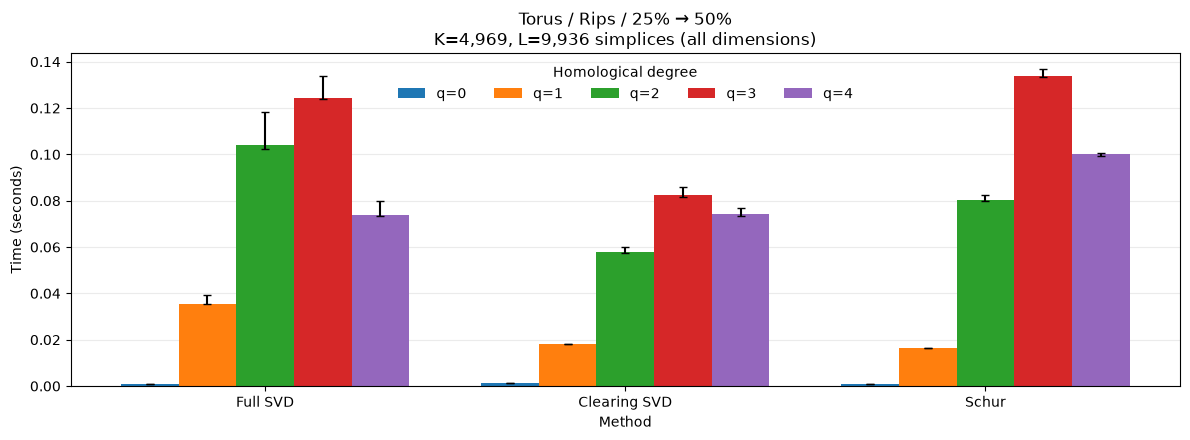

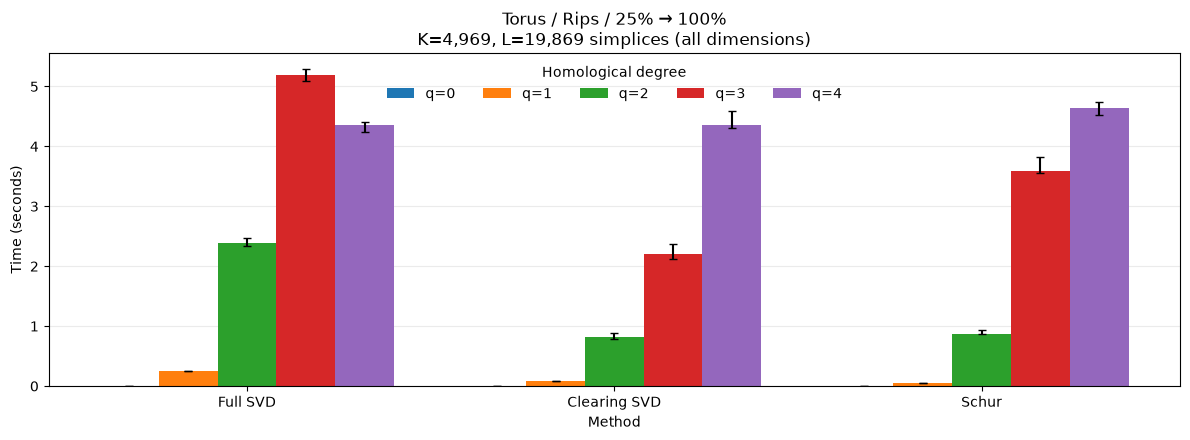

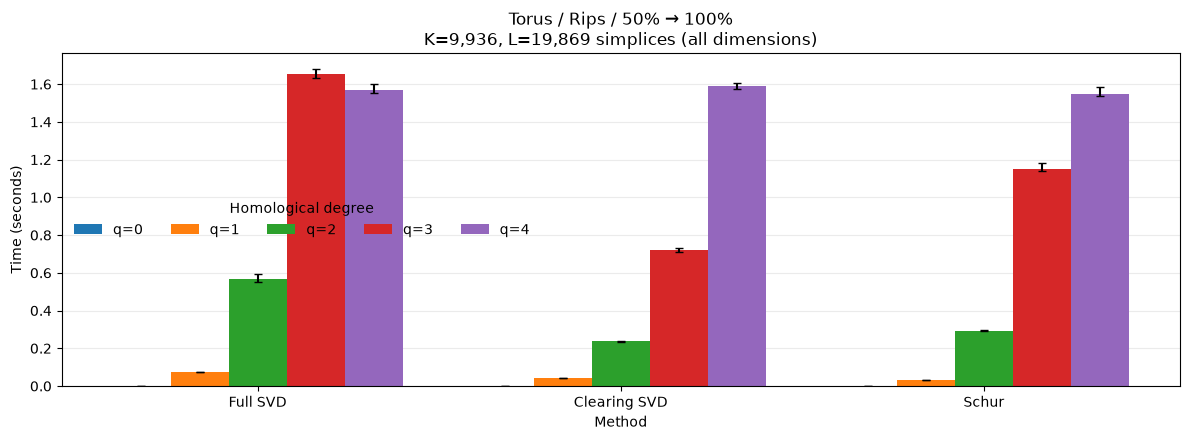

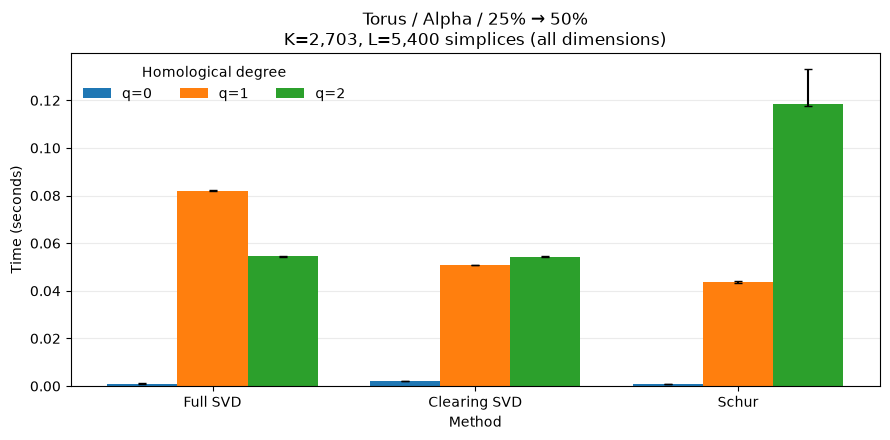

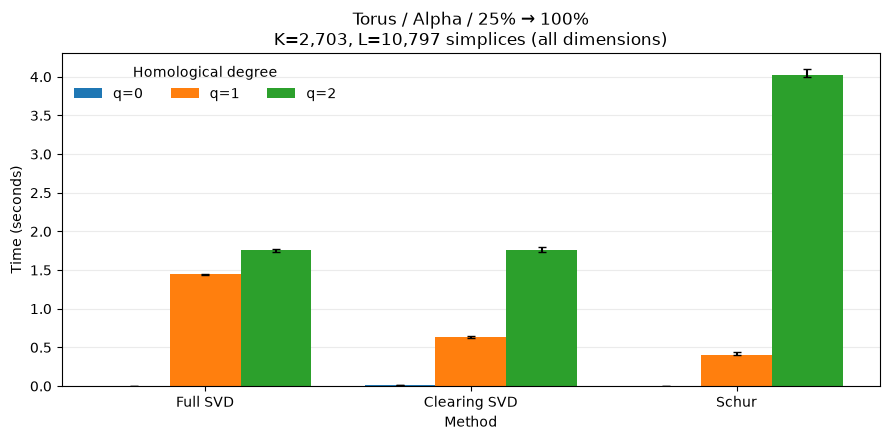

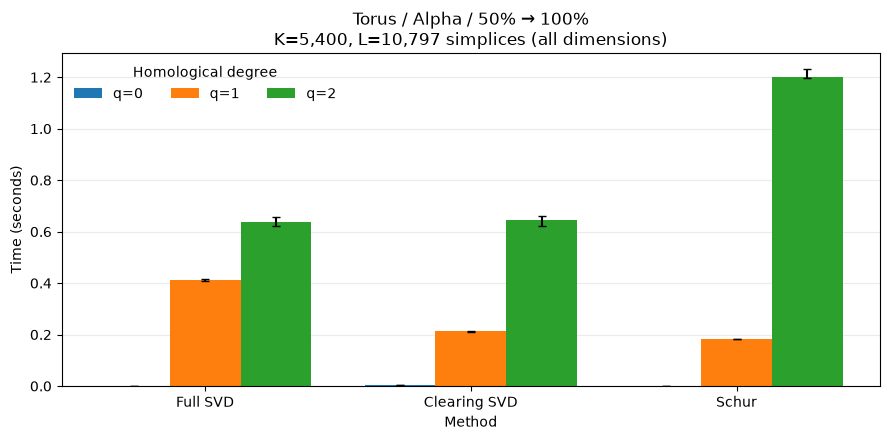

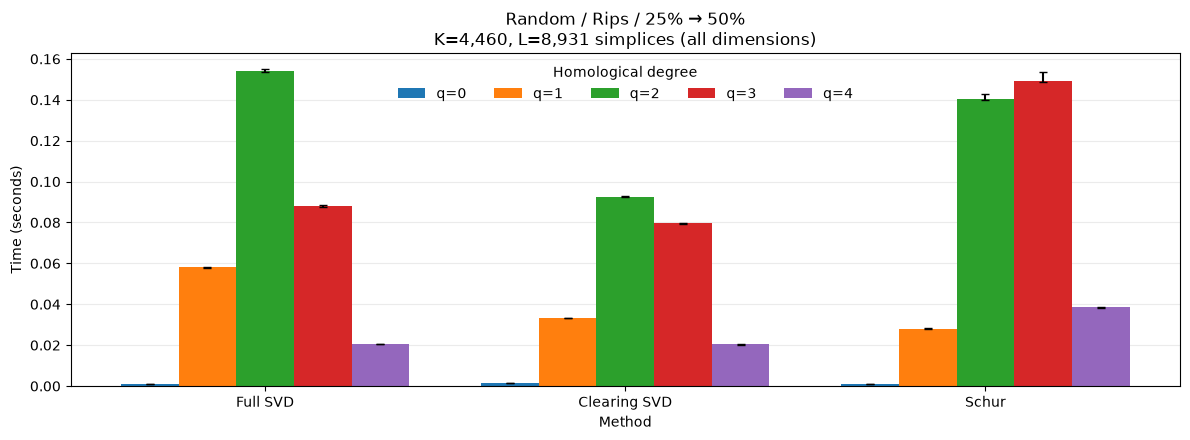

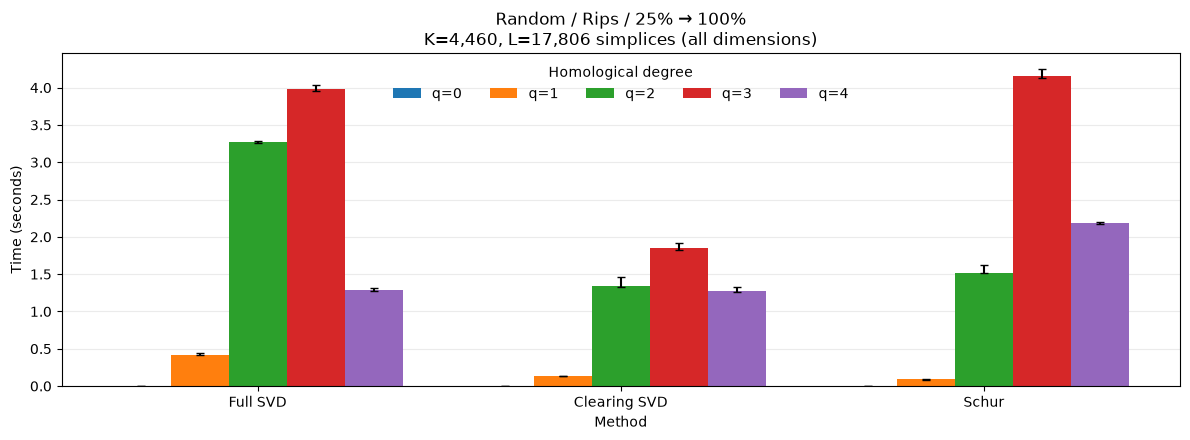

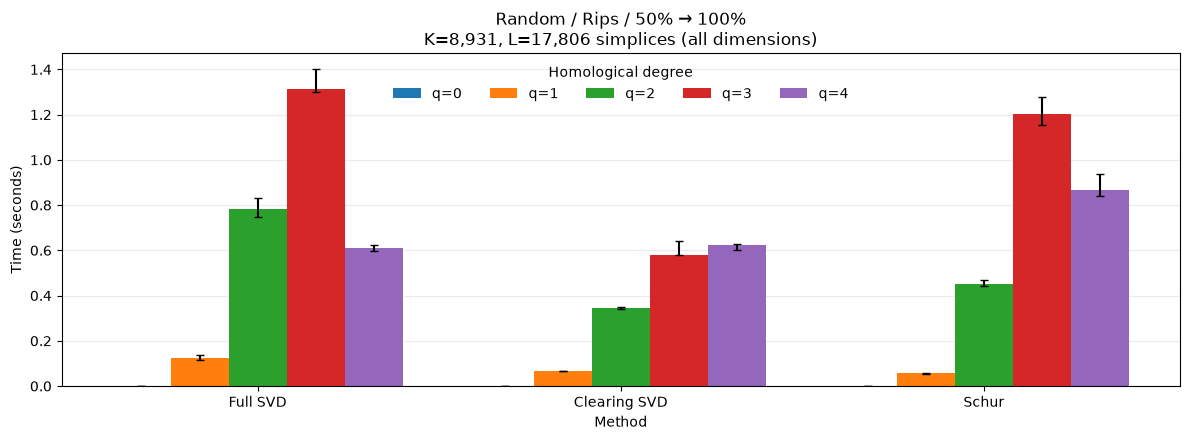

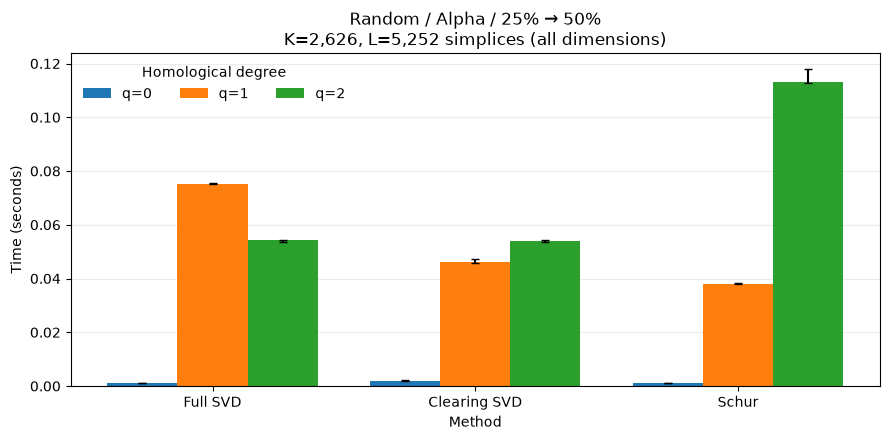

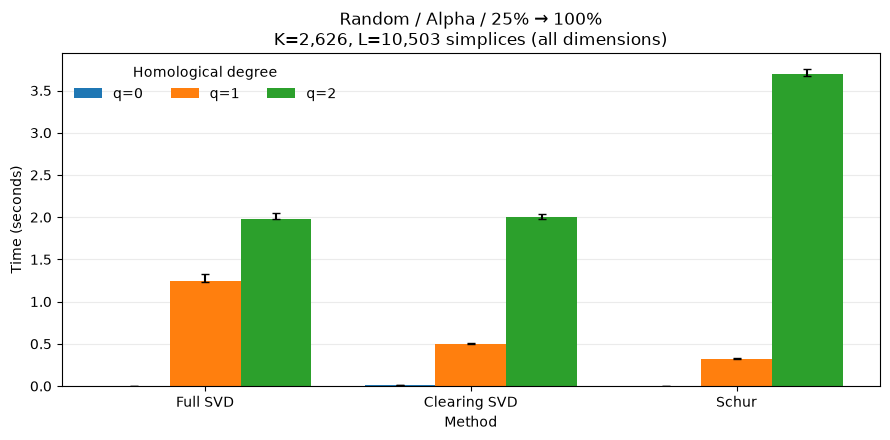

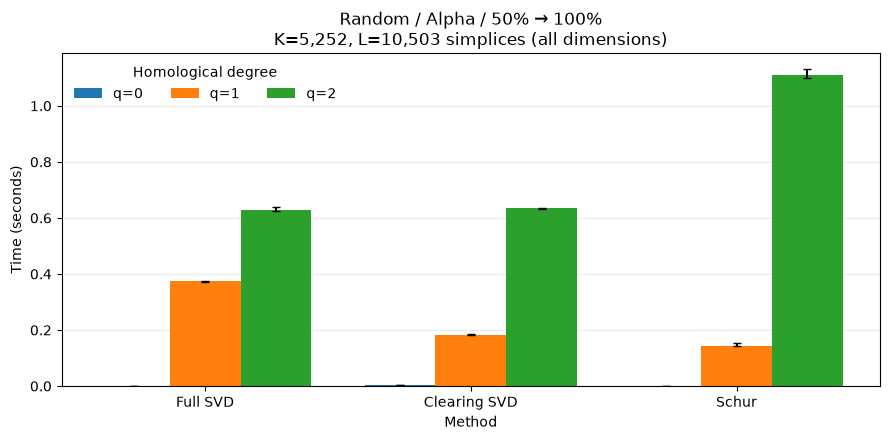

In [ ]:
timing_figures = plot_timings(summary)
plt.show()

# Example: plot_timings(summary, dataset="Torus", complex_type="Alpha", log=True)


In [ ]:
# Export only the timing figures, one per page, keeping their titles and labels.
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
with PdfPages(OUTPUT_DIR / "timing_plots.pdf") as pdf:
    for figure in timing_figures:
        pdf.savefig(figure, bbox_inches="tight")


## Matrix dimensions

Make one figure per **dataset / complex**, with a row for each K → L choice and
separate panels for row and column counts. The default plots show the boundary
slice $B_j$ and blocks $B_K,E,D$ at each homological degree.

Select a different algorithm and `matrices` to inspect recorded intermediates.
Skipped intermediates are omitted; these are shape counts, not measured memory.


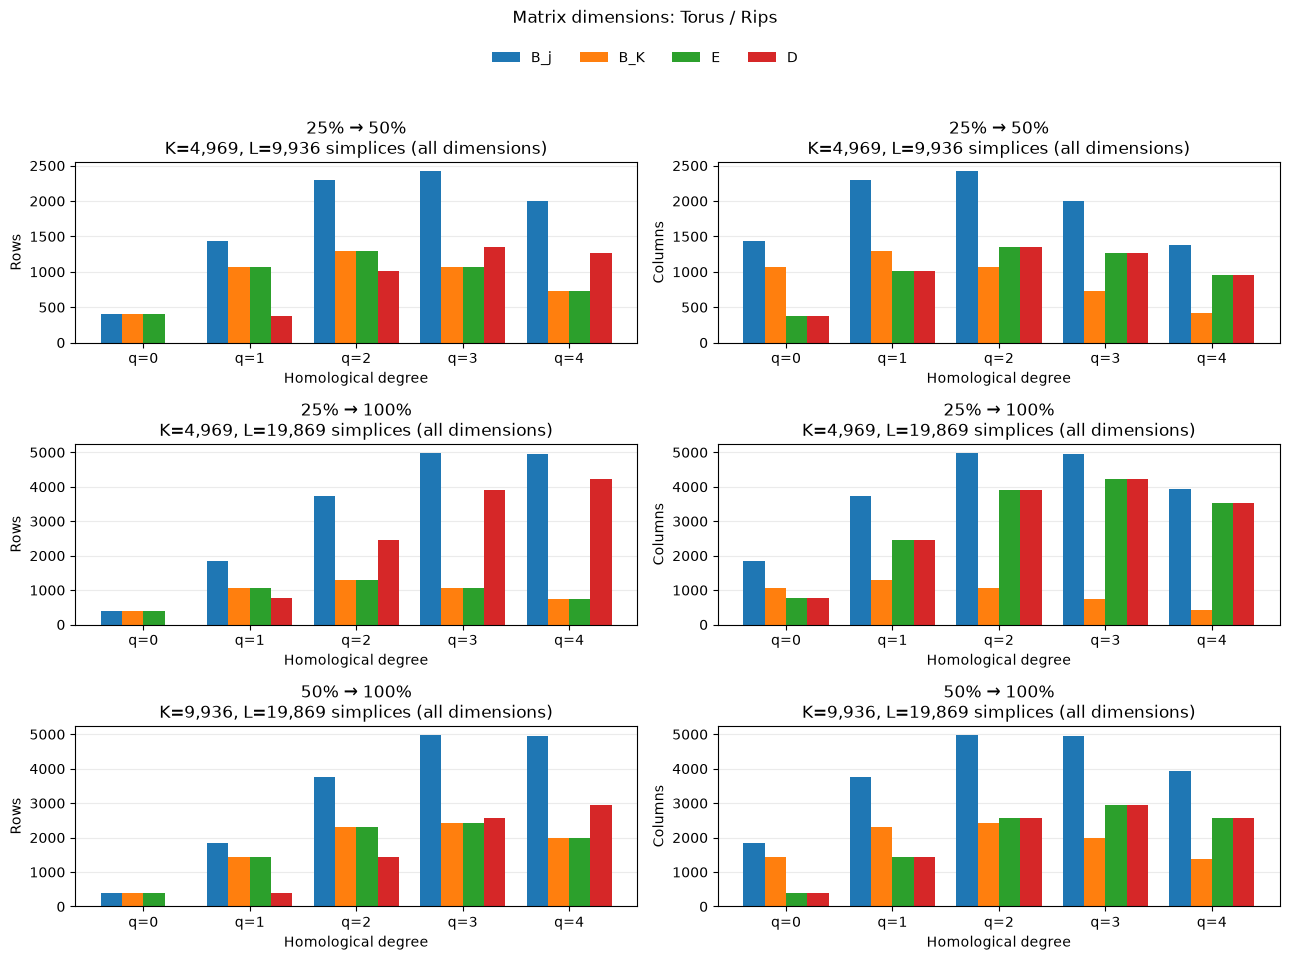

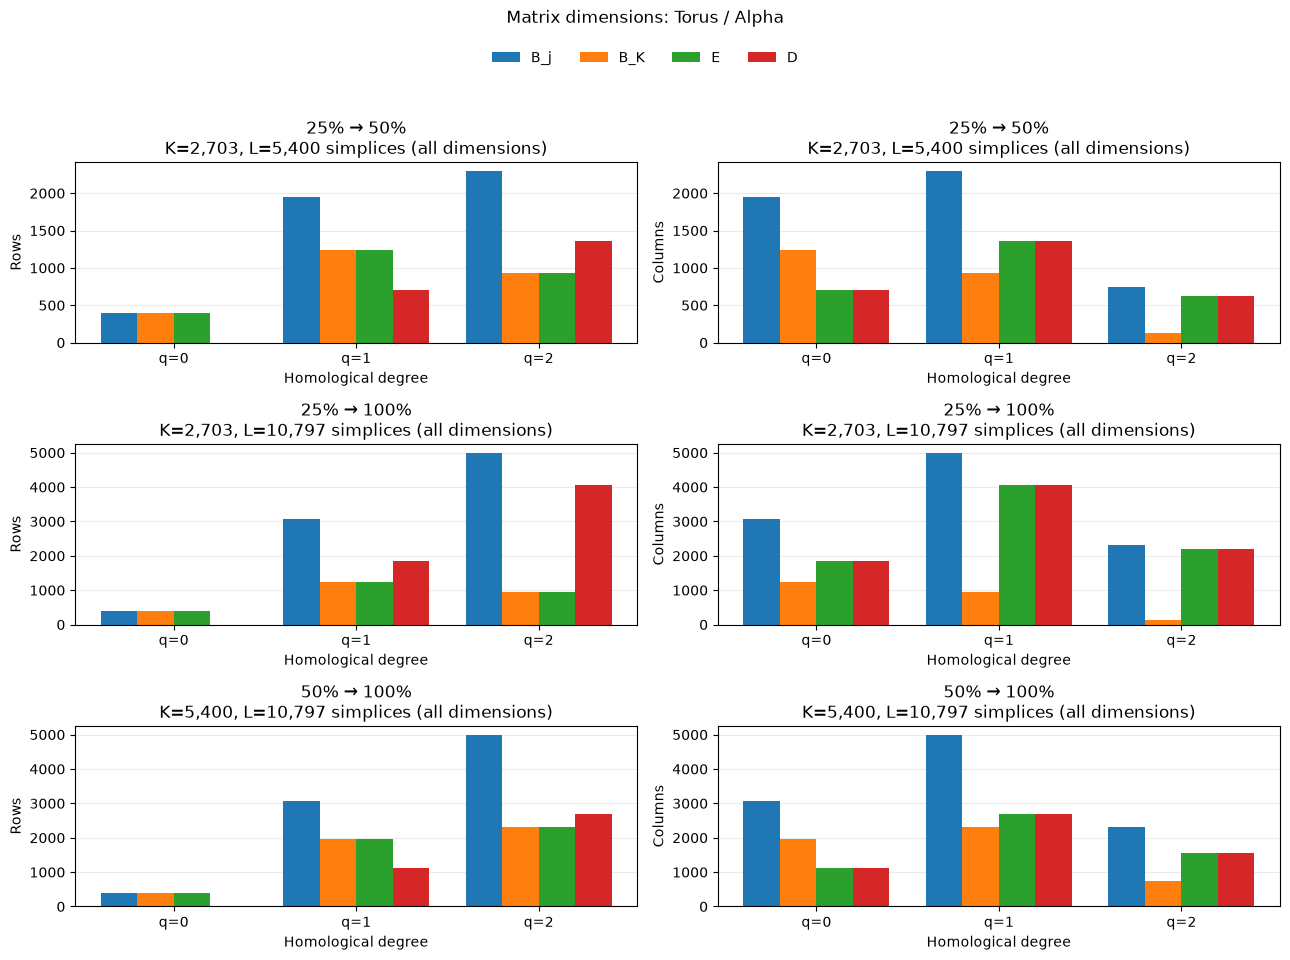

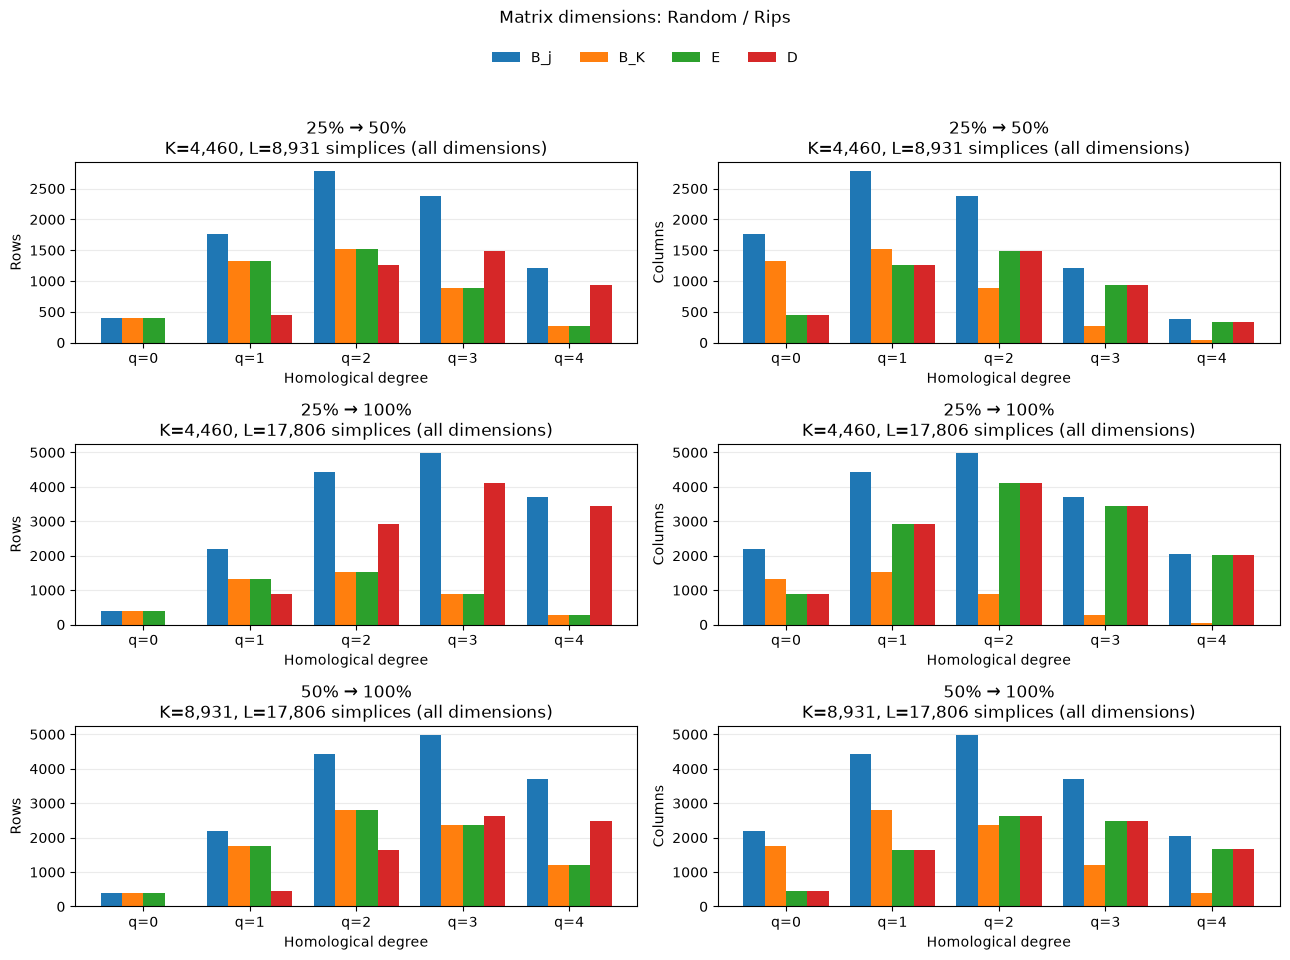

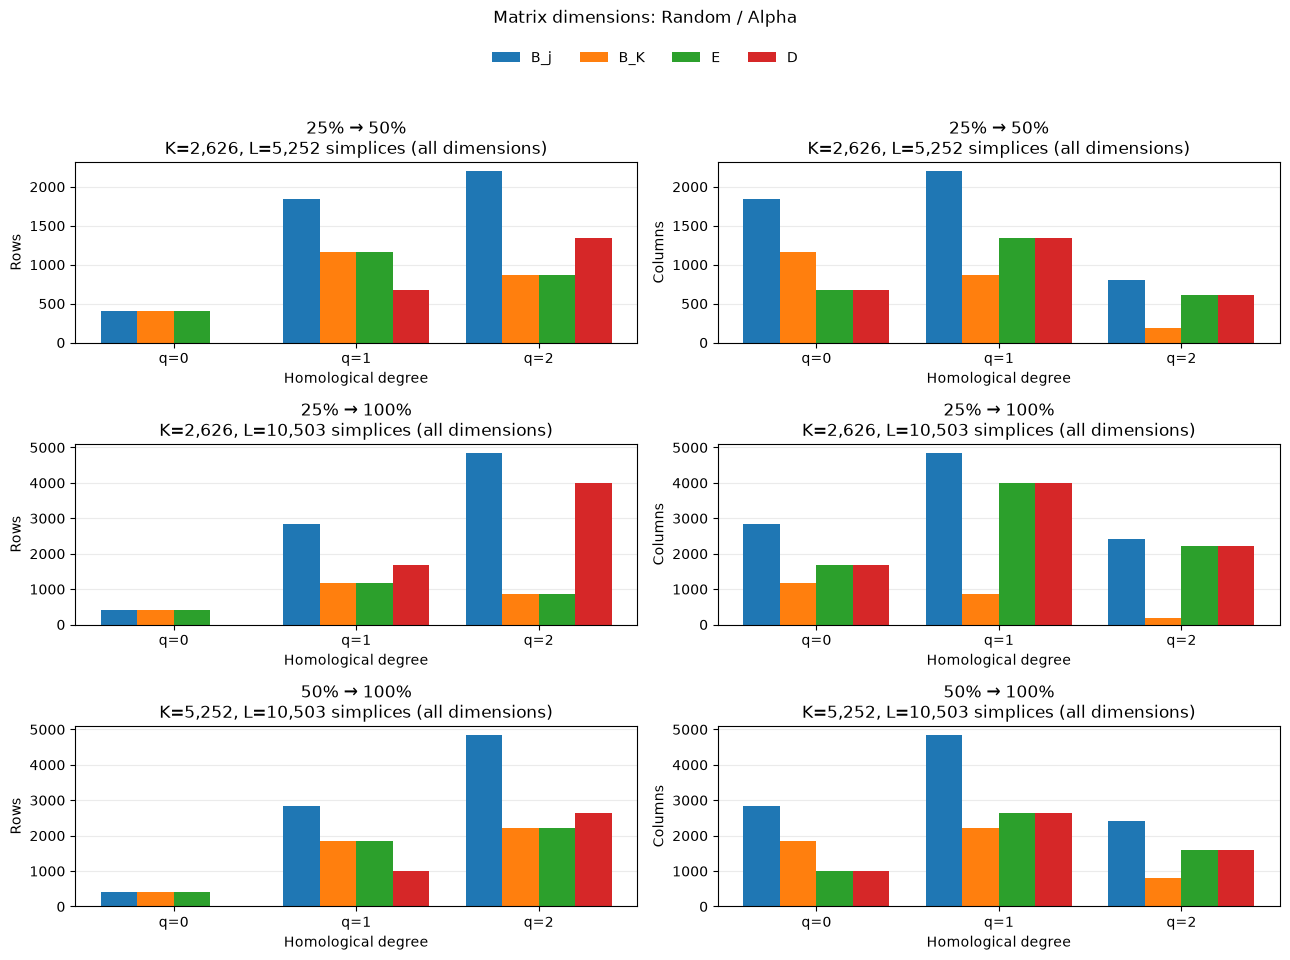

In [ ]:
dimension_figures = plot_matrix_sizes(matrix_sizes)
plt.show()

# Example: plot_matrix_sizes(matrix_sizes, dataset="Torus", method="Clearing SVD",
#                            matrices=("D", "compressed_D", "complement"))


## Save results or reload for plotting

CSV tables retain raw repetitions, summaries, endpoints, validation errors, and matrix
metadata. Reloading only requires the imports/configuration and plotting cells; it does
not rerun the experiment. The settings JSON records the data and numerical parameters.


In [8]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
for name, table in results.items():
    table.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)
settings = dict(n_points=N_POINTS, seed=SEED, repeats=REPEATS, boundary_limit=BOUNDARY_LIMIT,
                rips_dimension=RIPS_DIMENSION, rips_edge=RIPS_EDGE, fractions=FRACTIONS,
                torus=dict(c=2, a=1), random_box=[[-3, -3, -1], [3, 3, 1]],
                svd_rcond=SVD_RCOND, schur_rcond=SCHUR_RCOND)
(OUTPUT_DIR / "settings.json").write_text(json.dumps(settings, indent=2) + "\n")
print(f"Saved result tables to {OUTPUT_DIR.resolve()}")

# Reload later, then call either plotting function:
# summary = pd.read_csv(OUTPUT_DIR / "summary.csv")
# matrix_sizes = pd.read_csv(OUTPUT_DIR / "matrix_sizes.csv")
# plot_timings(summary, complex_type="Rips", log=True)


Saved result tables to /Users/mmasque/PhD/repositories/persistent-laplacians-benchmark/notebooks/dense_matrix_methods_results
